# Part 1 — Embedding-Based Transfer Learning (Word2Vec + IMDB)

**Goal:** take a pretrained `word2vec-google-news-300` model, inspect a few
words, *continue training* (fine-tune) those embeddings on IMDB review text,
and measure how the embedding space shifts.

**Rubric map**
1. Load pretrained Word2Vec &rarr; *Section 2*
2. Top-3 neighbours + cosine sim for `cast, score, plot, screen, review` (pretrained) &rarr; *Section 3*
3. Fine-tune embeddings on IMDB text &rarr; *Sections 4-5*
4. Re-extract top-3 neighbours after fine-tuning &rarr; *Section 6*
5. Both result sets in a table + 2D (t-SNE) shift visualisation for &ge;1 word &rarr; *Sections 7-8*
6. Cosine(original, fine-tuned) per word, table, most/least shifted &rarr; *Section 9*

> **Run this in Google Colab (CPU is fine here).** The pretrained model is
> ~1.6&nbsp;GB and downloads on first use.


## 1. Install & imports

In [1]:
# If a scipy "triu" error appears with older gensim, pin:  gensim>=4.3.3  scipy<1.13  numpy<2
!pip install -q gensim datasets scikit-learn matplotlib pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 22.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET_WORDS = ["cast", "score", "plot", "screen", "review"]
TOPN = 3


## 2. Load the pretrained Word2Vec model

In [3]:
# ~1.6 GB download the first time, then cached.
pretrained = api.load("word2vec-google-news-300")
print("Loaded pretrained vectors:", len(pretrained), "words,", pretrained.vector_size, "dims")


[==================================================] 100.0% 1662.8/1662.8MB downloaded
Loaded pretrained vectors: 3000000 words, 300 dims


## 3. Top-3 neighbours (PRETRAINED)

In [4]:
def neighbour_table(kv, words, topn=TOPN, tag="pretrained"):
    rows = []
    for w in words:
        if w not in kv:
            rows.append({"word": w, "rank": "-", "neighbor": "NOT IN VOCAB",
                         "cosine": np.nan, "model": tag})
            continue
        for rank, (nbr, sim) in enumerate(kv.most_similar(w, topn=topn), start=1):
            rows.append({"word": w, "rank": rank, "neighbor": nbr,
                         "cosine": round(float(sim), 4), "model": tag})
    return pd.DataFrame(rows)

pre_tbl = neighbour_table(pretrained, TARGET_WORDS, tag="pretrained")
pre_tbl


,word,rank,neighbor,cosine,model
0,cast,1,casts,0.7219,pretrained
1,cast,2,casting,0.7188,pretrained
2,cast,3,Cast,0.6638,pretrained
3,score,1,scoring,0.7197,pretrained
4,score,2,scores,0.6596,pretrained
5,score,3,scored,0.6384,pretrained
6,plot,1,plots,0.7625,pretrained
7,plot,2,Plot,0.6524,pretrained
8,plot,3,plotting,0.6328,pretrained
9,screen,1,screens,0.7729,pretrained


## 4. Load & preprocess the IMDB review text

We only need the raw text (unlabeled) to continue-train the embeddings, so we
merge every split into one corpus and tokenise with `simple_preprocess`.

In [12]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")   # canonical id; bare "imdb" alias breaks newer hub
texts = list(imdb["train"]["text"]) + list(imdb["test"]["text"]) + list(imdb["unsupervised"]["text"])
print("Raw reviews:", len(texts))

texts = list(imdb["train"]["text"]) + list(imdb["test"]["text"])   # 50k, not 100k
sentences = [simple_preprocess(t, deacc=True) for t in texts]
sentences = [s for s in sentences if len(s) > 2]
print("Usable tokenised reviews:", len(sentences))

Raw reviews: 100000
Usable tokenised reviews: 50000


## 5. Fine-tune (continue training) the embeddings

Recipe for *transfer learning* on embeddings:
1. Build a fresh skip-gram `Word2Vec` and build its vocab from IMDB.
2. **Warm-start**: overwrite each word's random vector with its pretrained
   Google-News vector (words not in Google-News keep their random init).
3. `train()` for a few epochs &rarr; the vectors move to fit movie-review usage.

Because we warm-start from the pretrained space and only train a few epochs, the
two spaces stay roughly aligned, so `cosine(original, fine-tuned)` for the *same*
word is meaningful (Section 9).

In [13]:
import logging
logging.basicConfig(format="%(asctime)s %(levelname)s %(message)s", level=logging.INFO)

w2v = Word2Vec(
    vector_size=300, window=5, min_count=5, sg=1,
    negative=5, workers=4, seed=RANDOM_STATE, epochs=5,
)
w2v.build_vocab(sentences)
print("IMDB vocab size:", len(w2v.wv))

shared = 0
for word in w2v.wv.index_to_key:
    if word in pretrained:
        w2v.wv.vectors[w2v.wv.key_to_index[word]] = pretrained[word]
        shared += 1
print("Seeded", shared, "/", len(w2v.wv), "from Google-News")

original_vecs = {w: pretrained[w].copy() for w in TARGET_WORDS if w in pretrained}

w2v.train(sentences, total_examples=w2v.corpus_count, epochs=w2v.epochs)
print("Fine-tuning done.")

IMDB vocab size: 39157
Seeded 32067 / 39157 from Google-News
Fine-tuning done.


## 6. Top-3 neighbours (FINE-TUNED)

In [14]:
ft_tbl = neighbour_table(w2v.wv, TARGET_WORDS, tag="fine-tuned")
ft_tbl


,word,rank,neighbor,cosine,model
0,cast,1,supporting,0.6398,fine-tuned
1,cast,2,ensemble,0.6035,fine-tuned
2,cast,3,actors,0.5830,fine-tuned
3,score,1,ennio,0.6540,fine-tuned
4,score,2,donaggio,0.6535,fine-tuned
5,score,3,music,0.6392,fine-tuned
6,plot,1,storyline,0.7184,fine-tuned
7,plot,2,story,0.6162,fine-tuned
8,plot,3,plotline,0.5820,fine-tuned
9,screen,1,screens,0.5599,fine-tuned


## 7. Both result sets in one table

In [15]:
combined = pd.concat([pre_tbl, ft_tbl], ignore_index=True)
# pivot to a compact side-by-side view: word x rank -> "neighbor (cos)"
def fmt(r):
    if pd.isna(r["cosine"]):
        return r["neighbor"]
    return f'{r["neighbor"]} ({r["cosine"]:.3f})'
combined["cell"] = combined.apply(fmt, axis=1)
side = combined.pivot_table(index="word", columns=["model", "rank"],
                            values="cell", aggfunc="first")
side = side.reindex(TARGET_WORDS)
side


model           fine-tuned                                      \
rank                     1                 2                 3   
word                                                             
cast    supporting (0.640)  ensemble (0.604)    actors (0.583)   
score        ennio (0.654)  donaggio (0.653)     music (0.639)   
plot     storyline (0.718)     story (0.616)  plotline (0.582)   
screen     screens (0.560)  onscreen (0.527)     stage (0.468)   
review     comment (0.661)   reviews (0.607)      imdb (0.560)   

model         pretrained                                         
rank                   1                  2                   3  
word                                                             
cast       casts (0.722)    casting (0.719)        Cast (0.664)  
score    scoring (0.720)     scores (0.660)      scored (0.638)  
plot       plots (0.762)       Plot (0.652)    plotting (0.633)  
screen   screens (0.773)   onscreen (0.612)  LCD_screen (0.560)  
review  reviewed (0.663)  reviewing (0.661)     reviews (0.638)

## 8. Visualise the shift in 2D (t-SNE)

We embed the **original** and **fine-tuned** vector of all 5 words together and
draw an arrow from each word's original position to its fine-tuned position.
(t-SNE is run on the joint set so both points live in the same 2D map.)

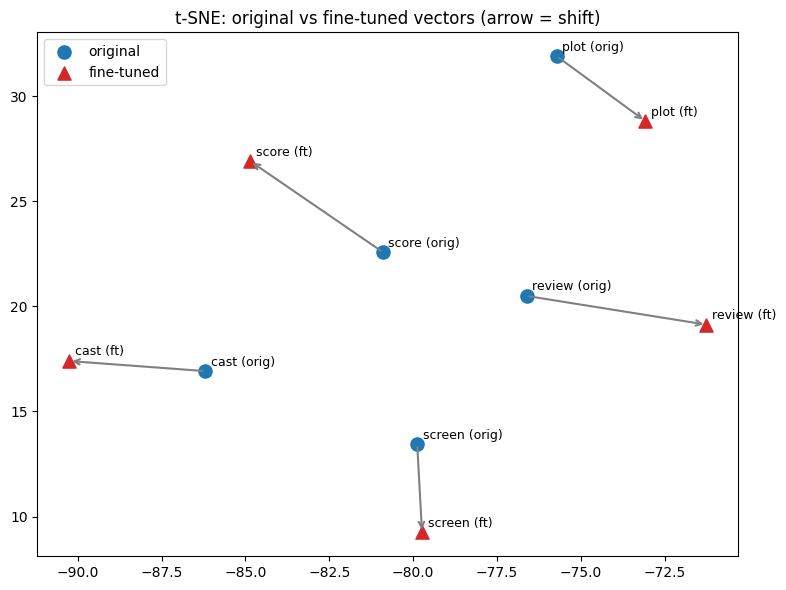

In [16]:
finetuned_vecs = {w: w2v.wv[w].copy() for w in TARGET_WORDS if w in w2v.wv}
words = [w for w in TARGET_WORDS if w in original_vecs and w in finetuned_vecs]

mat, labels, kinds = [], [], []
for w in words:
    mat.append(original_vecs[w]);  labels.append(w + " (orig)");  kinds.append("orig")
    mat.append(finetuned_vecs[w]); labels.append(w + " (ft)");   kinds.append("ft")
mat = np.array(mat, dtype=np.float32)

perp = max(2, min(5, len(mat) - 1))
emb2d = TSNE(n_components=2, perplexity=perp, init="pca",
            random_state=RANDOM_STATE, learning_rate="auto").fit_transform(mat)

plt.figure(figsize=(8, 6))
for i, (lab, k) in enumerate(zip(labels, kinds)):
    x, y = emb2d[i]
    plt.scatter(x, y, c=("tab:blue" if k == "orig" else "tab:red"),
                marker=("o" if k == "orig" else "^"), s=90,
                label=("original" if (k == "orig" and i == 0) else
                       "fine-tuned" if (k == "ft" and i == 1) else None))
    plt.annotate(lab, (x, y), fontsize=9, xytext=(4, 4), textcoords="offset points")

# arrows original -> fine-tuned per word
for i in range(0, len(mat), 2):
    x0, y0 = emb2d[i]; x1, y1 = emb2d[i + 1]
    plt.annotate("", xy=(x1, y1), xytext=(x0, y0),
                 arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))

plt.title("t-SNE: original vs fine-tuned vectors (arrow = shift)")
plt.legend(); plt.tight_layout(); plt.show()


## 9. Cosine(original, fine-tuned) per word — most / least shifted

Cosine close to **1.0** &rarr; the word barely moved. Lower cosine &rarr; bigger
semantic shift on movie-review text.

In [17]:
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

shift_rows = []
for w in words:
    c = cosine(original_vecs[w], finetuned_vecs[w])
    shift_rows.append({"word": w, "cosine_orig_vs_ft": round(c, 4),
                       "shift(1-cos)": round(1 - c, 4)})
shift_tbl = pd.DataFrame(shift_rows).sort_values("shift(1-cos)", ascending=False)
display(shift_tbl.reset_index(drop=True))

most  = shift_tbl.iloc[0]["word"]
least = shift_tbl.iloc[-1]["word"]
print(f"Most shifted : {most}")
print(f"Least shifted: {least}")


,word,cosine_orig_vs_ft,shift(1-cos)
0,review,0.4633,0.5367
1,score,0.4902,0.5098
2,plot,0.6032,0.3968
3,cast,0.6457,0.3543
4,screen,0.6819,0.3181


Most shifted : review
Least shifted: screen


### Interpretation (fill in from your run)

- The **most shifted** word is the one whose IMDB usage differs most from its
  general-news meaning (e.g. `score` &rarr; film music/rating rather than sports;
  `plot` &rarr; story rather than land/conspiracy).
- The **least shifted** word already meant roughly the same thing in both
  corpora, so training barely moved it.
- In the t-SNE plot, longer arrows correspond to the words with lower
  `cosine_orig_vs_ft` in the table above.
